#### Requirements

In [1]:
import pandas as pd
import numpy as np

import sys
sys.path.append("../..")

from src.backtester import calculate_return, backtester, backtester_v2
from src.strategies import run_momentum_strategy, generate_momentum_signal
from src.summary import summary

In [2]:
df = pd.read_csv("../../data/spy_daily.csv")
prices = df["Adj Close"]
returns = calculate_return(prices)
lookback = 252
returns_array = np.array(returns)

In [3]:
momentum_df, momentum_results = run_momentum_strategy(prices, returns, lookback, 0.001)
momentum_signal = generate_momentum_signal(prices, lookback)
momentum_position = momentum_df["position"]

#### Optimised Run Length Permutation Strategy

In [4]:
run_boundaries = []

run_boundaries.append(lookback + 1)

for i in range(lookback + 2, len(momentum_position)):
    if momentum_position.iloc[i] != momentum_position.iloc[i - 1]:
        run_boundaries.append(i)

run_boundaries.append(len(momentum_position))

In [5]:
run_lengths = []

for i in range(1, len(run_boundaries)):
    difference = float(run_boundaries[i]) - float(run_boundaries[i - 1])

    run_lengths.append(difference)

In [6]:
cash_runs = run_lengths[::2]
invested_runs = run_lengths[1::2]

In [7]:
def generate_random_signal_v5(cash_runs, invested_runs, lookback):

    random_cash_sequence = np.random.permutation(cash_runs).astype(int)
    random_invested_sequence = np.random.permutation(invested_runs).astype(int)

    sequence = []
        
    for i in range(len(cash_runs)):
        
        sequence.extend([0] * random_cash_sequence[i])
        sequence.extend([1] * random_invested_sequence[i])
    
    sequence.append(np.nan)
    
    random_signal = ([np.nan] * lookback) + sequence

    return random_signal

In [8]:
def run_simulation_v5(n):

    simulation_result = []

    for i in range(n):

        random_signal = generate_random_signal_v5(cash_runs, invested_runs, lookback)
        random_result = backtester_v2(returns_array, random_signal, 0.001)

        simulation_result.append(random_result)

    return simulation_result

In [9]:
np.random.seed(44)

simulation_output = run_simulation_v5(100000)
simulation_df = pd.DataFrame(simulation_output)
simulation_df

,total_return,cagr,annual_volatility,annual_sharpe,max_drawdown,calmar,time_invested,trades
0,10.880236,0.101357,0.137969,0.768838,-0.313847,0.322950,0.775232,89
1,5.539611,0.076005,0.161014,0.535479,-0.367422,0.206859,0.775232,89
2,4.644221,0.069842,0.174890,0.473505,-0.536205,0.130252,0.775232,89
3,3.623271,0.061547,0.163593,0.446895,-0.551895,0.111519,0.775232,89
4,3.431431,0.059793,0.172358,0.423175,-0.551895,0.108342,0.775232,89
...,...,...,...,...,...,...,...,...
99995,5.694756,0.076989,0.172809,0.515731,-0.564813,0.136309,0.775232,89
99996,2.243434,0.046969,0.181375,0.343790,-0.596809,0.078701,0.775232,89
99997,9.180905,0.094745,0.155471,0.660175,-0.422290,0.224360,0.775232,89
99998,3.007847,0.055648,0.175584,0.396344,-0.548294,0.101493,0.775232,89


Mean Sharpe: 0.47382
Median Sharpe: 0.46005
Max Sharpe: 0.98464
P Value: 0.07784
Avg Trades: 89
Avg Time Invested: 0.77523
Number Of Simulations: 100000


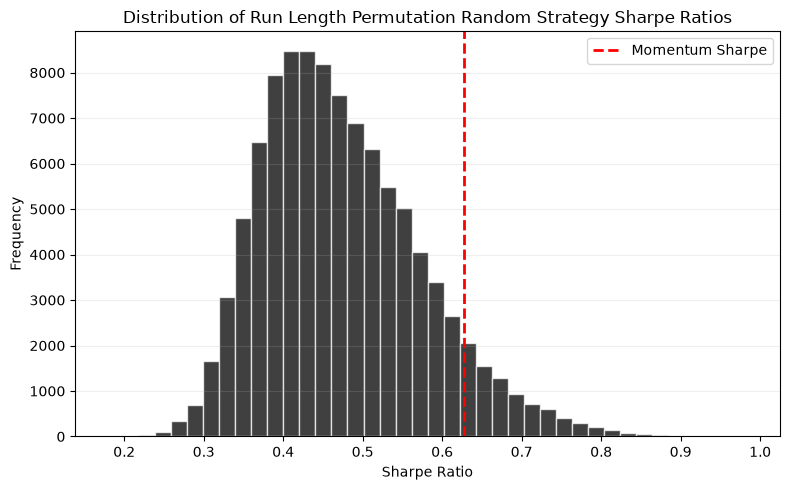

In [10]:
run_length_summary = summary(simulation_df, momentum_results, "run_length_permutation_random_strategy")